Name: Ivy Cheng

Github Username: ivychengusc

USC ID: 6931463618

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import hamming_loss, silhouette_score
from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import calinski_harabasz_score

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

### 1(a)

In [3]:
DATA_PATH = "../data/Homework 7 Data/Frogs_MFCCs.csv"
df = pd.read_csv(DATA_PATH)

train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=552
)

print("Full dataset shape:", df.shape)
print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

Full dataset shape: (7195, 26)
Training set shape: (5036, 26)
Test set shape: (2159, 26)


### 1(b)(i)

Exact match requires all labels to be correct. Hamming loss is the fraction of incorrectly predicted labels, and Hamming score is $1-$ Hamming loss.

In [8]:
def evaluate_multilabel(y_true, y_pred):
    exact_match = np.mean(np.all(y_true == y_pred, axis=1))
    h_loss = np.mean(y_true != y_pred)
    h_score = 1 - h_loss

    return exact_match, h_score, h_loss

### 1(b)(ii)

In [9]:
X_train = train_df.iloc[:, :22]
X_test = test_df.iloc[:, :22]

label_cols = ["Family", "Genus", "Species"]

param_grid = {
    "estimator__C": [0.1, 1, 10, 100],
    "estimator__gamma": [0.01, 0.1, 1]
}

rbf_models = {}
rbf_predictions = {}
rbf_params = []

for label in label_cols:
    model = OneVsRestClassifier(SVC(kernel="rbf"))

    grid = GridSearchCV(
        model,
        param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, train_df[label])

    rbf_models[label] = grid.best_estimator_
    rbf_predictions[label] = grid.predict(X_test)

    rbf_params.append([
        label,
        grid.best_params_["estimator__C"],
        grid.best_params_["estimator__gamma"]
    ])

pd.DataFrame(rbf_params, columns=["Label", "Best C", "Best Gamma"])

,Label,Best C,Best Gamma
0,Family,100,1
1,Genus,100,1
2,Species,10,1


In [10]:
y_true = test_df[label_cols].to_numpy()

y_pred_rbf = np.column_stack([
    rbf_predictions[label] for label in label_cols
])

exact_rbf, hscore_rbf, hloss_rbf = evaluate_multilabel(
    y_true, y_pred_rbf
)

pd.DataFrame({
    "Exact Match": [exact_rbf],
    "Hamming Score": [hscore_rbf],
    "Hamming Loss": [hloss_rbf]
})

,Exact Match,Hamming Score,Hamming Loss
0,0.982399,0.989038,0.010962


### 1(b)(iii)

In [12]:
l1_models = {}
l1_predictions = {}
l1_params = []

for label in label_cols:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        {"svm__C": [0.01, 0.1, 1, 10, 100]},
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, train_df[label])

    l1_models[label] = grid.best_estimator_
    l1_predictions[label] = grid.predict(X_test)
    l1_params.append([label, grid.best_params_["svm__C"]])

pd.DataFrame(l1_params, columns=["Label", "Best C"])

,Label,Best C
0,Family,1
1,Genus,10
2,Species,10


In [13]:
y_pred_l1 = np.column_stack([
    l1_predictions[label] for label in label_cols
])

exact_l1, hscore_l1, hloss_l1 = evaluate_multilabel(
    y_true, y_pred_l1
)

pd.DataFrame({
    "Exact Match": [exact_l1],
    "Hamming Score": [hscore_l1],
    "Hamming Loss": [hloss_l1]
})

,Exact Match,Hamming Score,Hamming Loss
0,0.917091,0.947352,0.052648


### 1(b)(iv)

In [17]:
smote_predictions = {}
smote_params = []

for label in label_cols:
    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=552)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=100000
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        {"svm__C": [0.01, 0.1, 1, 10, 100]},
        cv=10,
        scoring="accuracy",
        n_jobs=1
    )

    grid.fit(X_train, train_df[label])

    smote_predictions[label] = grid.predict(X_test)
    smote_params.append([label, grid.best_params_["svm__C"]])

pd.DataFrame(smote_params, columns=["Label", "Best C"])

,Label,Best C
0,Family,100
1,Genus,10
2,Species,100


In [18]:
y_pred_smote = np.column_stack([
    smote_predictions[label] for label in label_cols
])

exact_smote, hscore_smote, hloss_smote = evaluate_multilabel(
    y_true, y_pred_smote
)

pd.DataFrame({
    "Model": ["L1 SVM", "L1 SVM + SMOTE"],
    "Exact Match": [exact_l1, exact_smote],
    "Hamming Score": [hscore_l1, hscore_smote],
    "Hamming Loss": [hloss_l1, hloss_smote]
})

,Model,Exact Match,Hamming Score,Hamming Loss
0,L1 SVM,0.917091,0.947352,0.052648
1,L1 SVM + SMOTE,0.863826,0.924965,0.075035


SMOTE did not improve the L1 SVM in this dataset. Exact match and Hamming score decreased, while Hamming loss increased.

### 2(a)

In [20]:
X_all = df.iloc[:, :22]

def choose_k(X, random_state):
    scores = []

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            random_state=random_state,
            n_init=10
        )
        clusters = model.fit_predict(X)
        scores.append(calinski_harabasz_score(X, clusters))

    return np.argmax(scores) + 2

### 2(b)

In [22]:
true_labels = df[label_cols].reset_index(drop=True)

def get_cluster_majorities(clusters, k):
    majority_labels = {}

    for cluster in range(k):
        idx = clusters == cluster
        majority_labels[cluster] = {
            label: true_labels.loc[idx, label].mode()[0]
            for label in label_cols
        }

    return majority_labels

### 2(c)

In [24]:
def run_once(seed):
    k = choose_k(X_all, seed)

    model = KMeans(
        n_clusters=k,
        random_state=seed,
        n_init=10
    )

    clusters = model.fit_predict(X_all)
    majorities = get_cluster_majorities(clusters, k)

    y_pred = np.array([
        [majorities[c][label] for label in label_cols]
        for c in clusters
    ])

    y_true_all = true_labels.to_numpy()

    h_distance = np.mean(np.sum(y_true_all != y_pred, axis=1))
    h_loss = np.mean(y_true_all != y_pred)
    h_score = 1 - h_loss

    return k, h_distance, h_score, h_loss


results = [run_once(i) for i in range(50)]

mc_results = pd.DataFrame(
    results,
    columns=["k", "Hamming Distance", "Hamming Score", "Hamming Loss"]
)

pd.DataFrame({
    "Metric": ["Hamming Distance", "Hamming Score", "Hamming Loss"],
    "Mean": [
        mc_results["Hamming Distance"].mean(),
        mc_results["Hamming Score"].mean(),
        mc_results["Hamming Loss"].mean()
    ],
    "Standard Deviation": [
        mc_results["Hamming Distance"].std(ddof=1),
        mc_results["Hamming Score"].std(ddof=1),
        mc_results["Hamming Loss"].std(ddof=1)
    ]
})

,Metric,Mean,Standard Deviation
0,Hamming Distance,0.895622,1.121495e-16
1,Hamming Score,0.701459,3.364484e-16
2,Hamming Loss,0.298541,1.682242e-16


The average Hamming distance is 0.8956, with Hamming score 0.7015 and Hamming loss 0.2985. The standard deviations are approximately zero.

### 12.6.2

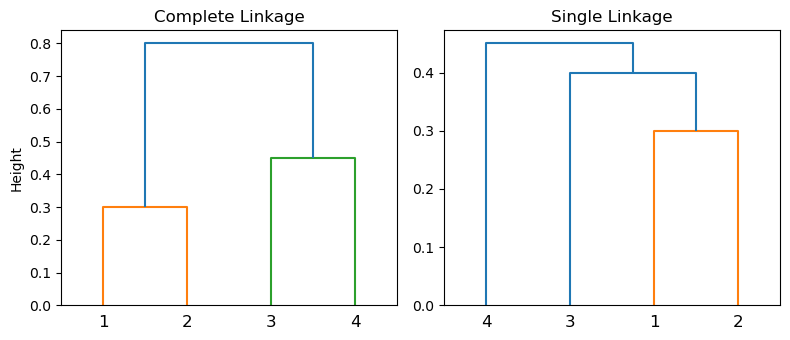

In [26]:
D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

dist = squareform(D)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

Z_complete = linkage(dist, method="complete")
dendrogram(Z_complete, labels=["1", "2", "3", "4"], ax=axes[0])
axes[0].set_title("Complete Linkage")
axes[0].set_ylabel("Height")

Z_single = linkage(dist, method="single")
dendrogram(Z_single, labels=["1", "2", "3", "4"], ax=axes[1])
axes[1].set_title("Single Linkage")

plt.tight_layout()
plt.show()

(a) Complete linkage merges observations 1 and 2 at 0.30, observations 3 and 4 at 0.45, and the two clusters at 0.80.

(b) Single linkage merges observations 1 and 2 at 0.30, then observation 3 joins at 0.40, and observation 4 joins at 0.45.

(c) Complete linkage with two clusters:
$$
\{1,2\},\qquad \{3,4\}.
$$

(d) Single linkage with two clusters:
$$
\{1,2,3\},\qquad \{4\}.
$$

(e) An equivalent complete-linkage dendrogram can use the leaf order
$$
2,\ 1,\ 4,\ 3,
$$
while keeping the same fusion heights 0.30, 0.45, and 0.80.